<a href="https://colab.research.google.com/github/addisonschleigh/CMPE131-Activity-Project-Prototype/blob/main/CMPE_188_Project_Group_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [233]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("06_german_credit_risk_train.csv")
df.head()

,checking_account_status,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate_pct,personal_status_sex,other_debtors_guarantors,...,property,age,other_installment_plans,housing,existing_credits_count,job,num_dependents,telephone,foreign_worker,credit_risk
0,A12,18,A32,A43,866,A61,A73,4,A94,A103,...,A121,25,A143,A152,1,A172,1,A191,A201,1
1,A14,10,A34,A42,2146,A61,A72,1,A92,A101,...,A121,23,A143,A151,2,A173,1,A191,A201,1
2,A11,6,A34,A40,609,A61,A74,4,A92,A101,...,A122,37,A143,A152,2,A173,1,A191,A202,1
3,A14,48,A34,A41,2751,A65,A75,4,A93,A101,...,A123,38,A143,A152,2,A173,2,A192,A201,1
4,A14,60,A33,A43,15653,A61,A74,2,A93,A101,...,A123,21,A143,A152,2,A173,1,A192,A201,1


In [234]:
df.shape

(850, 21)

In [235]:
nominal = ['checking_account_status','credit_history','purpose','savings_account','employment_since','personal_status_sex','other_debtors_guarantors','property','other_installment_plans','housing','job','telephone','foreign_worker']
numeric = ['duration_months','credit_amount','installment_rate_pct','present_residence_since','age','existing_credits_count','num_dependents']
print("Nominal length: ", len(nominal))
print("Numeric length: ", len(numeric))

Nominal length:  13
Numeric length:  7


In [236]:
x = df.drop("credit_risk", axis=1)
y = df["credit_risk"]

Attribute info:  
Attribute 1:  (qualitative)      
 Status of existing checking account
             A11 :      ... <    0 DM
	       A12 : 0 <= ... <  200 DM
	       A13 :      ... >= 200 DM / salary assignments for at least 1 year
               A14 : no checking account

Attribute 2:  (numerical)
	      Duration in month

Attribute 3:  (qualitative)
	      Credit history
	      A30 : no credits taken/ all credits paid back duly
              A31 : all credits at this bank paid back duly
	      A32 : existing credits paid back duly till now
              A33 : delay in paying off in the past
	      A34 : critical account/  other credits existing (not at this bank)

Attribute 4:  (qualitative)
	      Purpose
	      A40 : car (new)
	      A41 : car (used)
	      A42 : furniture/equipment
	      A43 : radio/television
	      A44 : domestic appliances
	      A45 : repairs
	      A46 : education
	      A47 : (vacation - does not exist?)
	      A48 : retraining
	      A49 : business
	      A410 : others

Attribute 5:  (numerical)
	      Credit amount

Attibute 6:  (qualitative)
	      Savings account/bonds
	      A61 :          ... <  100 DM
	      A62 :   100 <= ... <  500 DM
	      A63 :   500 <= ... < 1000 DM
	      A64 :          .. >= 1000 DM
              A65 :   unknown/ no savings account

Attribute 7:  (qualitative)
	      Present employment since
	      A71 : unemployed
	      A72 :       ... < 1 year
	      A73 : 1  <= ... < 4 years  
	      A74 : 4  <= ... < 7 years
	      A75 :       .. >= 7 years

Attribute 8:  (numerical)
	      Installment rate in percentage of disposable income

Attribute 9:  (qualitative)
	      Personal status and sex
	      A91 : male   : divorced/separated
	      A92 : female : divorced/separated/married
              A93 : male   : single
	      A94 : male   : married/widowed
	      A95 : female : single

Attribute 10: (qualitative)
	      Other debtors / guarantors
	      A101 : none
	      A102 : co-applicant
	      A103 : guarantor

Attribute 11: (numerical)
	      Present residence since

Attribute 12: (qualitative)
	      Property
	      A121 : real estate
	      A122 : if not A121 : building society savings agreement/ life insurance
              A123 : if not A121/A122 : car or other, not in attribute 6
	      A124 : unknown / no property

Attribute 13: (numerical)
	      Age in years

Attribute 14: (qualitative)
	      Other installment plans
	      A141 : bank
	      A142 : stores
	      A143 : none

Attribute 15: (qualitative)
	      Housing
	      A151 : rent
	      A152 : own
	      A153 : for free

Attribute 16: (numerical)
              Number of existing credits at this bank

Attribute 17: (qualitative)
	      Job
	      A171 : unemployed/ unskilled  - non-resident
	      A172 : unskilled - resident
	      A173 : skilled employee / official
	      A174 : management/ self-employed/
		     highly qualified employee/ officer

Attribute 18: (numerical)
	      Number of people being liable to provide maintenance for

Attribute 19: (qualitative)
	      Telephone
	      A191 : none
	      A192 : yes, registered under the customers name

Attribute 20: (qualitative)
	      foreign worker
	      A201 : yes
	      A202 : no

In [237]:
df["checking_account_status"].value_counts()

,count
checking_account_status,
A14,336
A11,232
A12,231
A13,51


In [238]:
df["credit_history"].value_counts()

,count
credit_history,
A32,451
A34,251
A33,74
A31,43
A30,31


In [239]:
df['employment_since'].value_counts()

,count
employment_since,
A73,289
A75,216
A72,152
A74,145
A71,48


In [240]:
df['savings_account'].value_counts()

,count
savings_account,
A61,512
A65,156
A62,87
A63,56
A64,39


In [241]:
y = (df["credit_risk"])
y.value_counts()

,count
credit_risk,
1,595
2,255


In [242]:
print("Credit Risk Good: ", y.value_counts()[1])
print("Credit Risk Bad: ", y.value_counts()[2])
print("Total: ", y.value_counts().sum())

Credit Risk Good:  595
Credit Risk Bad:  255
Total:  850


In [243]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

# Build preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal)
    ]
)

Logistic Regression:

In [244]:
# Combine preprocessing and logistic regression into one pipeline
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit directly on raw X_train
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  0.788235294117647


Decision Trees:

In [245]:
def entropy(counts):
    counts = np.asarray(counts, dtype=float)
    counts = counts[counts > 0]
    p = counts / counts.sum()
    return -(p * np.log2(p)).sum() + 0.0          # + 0.0 turns -0.0 into 0.0

def info_gain(parent_counts, children_counts):
    n = sum(sum(c) for c in children_counts)
    remainder = sum(sum(c) / n * entropy(c) for c in children_counts)
    return entropy(parent_counts) - remainder

In [246]:
# Define FEATURES and ensure we use X_train consistently
FEATURES = X_train.columns.tolist()

# Helper function to compute entropy
def entropy(y_subset):
    if len(y_subset) == 0:
        return 0.0
    p = y_subset.value_counts(normalize=True)
    return -np.sum(p * np.log2(p + 1e-12))

# Helper function to compute information gain
def info_gain(parent_entropy, kids_counts):
    total_instances = sum(sum(kid) for kid in kids_counts)
    if total_instances == 0:
        return 0.0

    weighted_child_entropy = 0.0
    for kid in kids_counts:
        kid_sum = sum(kid)
        if kid_sum == 0:
            continue
        probs = [count / kid_sum for count in kid]
        kid_entropy = -sum(p * np.log2(p + 1e-12) for p in probs if p > 0)
        weighted_child_entropy += (kid_sum / total_instances) * kid_entropy

    return parent_entropy - weighted_child_entropy

# Calculate parent entropy
parent = entropy(y_train)

# A fair comparison: the best yes/no split for EVERY column, the way sklearn searches.
def best_binary_gain(col):
    x = X_train[col].values
    # If the column is categorical (strings), we can't do numeric splits with mathematical addition/division
    if col in nominal:
        # For categorical attributes, use unique categories as potential split points
        cuts = np.unique(x)
        best = (0.0, None)
        for t in cuts:
            left = x == t
            kids = [[(y_train[left] == 1).sum(), (y_train[left] == 2).sum()], [(y_train[~left] == 1).sum(), (y_train[~left] == 2).sum()]]
            g = info_gain(parent, kids)
            if g > best[0]: best = (g, t)
        return best
    else:
        # For numeric columns, use standard midpoint splits
        cuts = (np.unique(x)[:-1] + np.unique(x)[1:]) / 2
        best = (0.0, None)
        for t in cuts:
            left = x <= t
            kids = [[(y_train[left] == 1).sum(), (y_train[left] == 2).sum()], [(y_train[~left] == 1).sum(), (y_train[~left] == 2).sum()]]
            g = info_gain(parent, kids)
            if g > best[0]: best = (g, t)
        return best

gains = pd.DataFrame({c: best_binary_gain(c) for c in FEATURES}, index=["info_gain", "threshold"]).T.sort_values("info_gain", ascending=False)
gains.head(8)

,info_gain,threshold
checking_account_status,0.080126,A14
duration_months,0.02481,8.5
credit_amount,0.023193,10918.0
credit_history,0.022924,A34
housing,0.01727,A152
savings_account,0.015874,A61
property,0.013666,A124
other_installment_plans,0.013024,A143


In [247]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', tree)
])

clf.fit(X_train, y_train)

# Get the feature names after preprocessing
transformed_features = clf.named_steps['preprocessor'].get_feature_names_out()

y_pred = clf.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  0.6588235294117647


In [248]:
root = tree.tree_.feature[0]
print("sklearn root:", transformed_features[root], "<=", tree.tree_.threshold[0])
print("hand-computed best:", gains.index[0], "<=", gains.iloc[0, 1])
print()
print(export_text(tree, feature_names=list(transformed_features), show_weights=True))

sklearn root: cat__checking_account_status_A14 <= 0.5
hand-computed best: checking_account_status <= A14

|--- cat__checking_account_status_A14 <= 0.50
|   |--- num__duration_months <= 0.14
|   |   |--- cat__housing_A152 <= 0.50
|   |   |   |--- num__age <= -1.05
|   |   |   |   |--- num__credit_amount <= -0.54
|   |   |   |   |   |--- weights: [7.00, 5.00] class: 1
|   |   |   |   |--- num__credit_amount >  -0.54
|   |   |   |   |   |--- weights: [6.00, 0.00] class: 1
|   |   |   |--- num__age >  -1.05
|   |   |   |   |--- cat__foreign_worker_A202 <= 0.50
|   |   |   |   |   |--- weights: [17.00, 29.00] class: 2
|   |   |   |   |--- cat__foreign_worker_A202 >  0.50
|   |   |   |   |   |--- weights: [2.00, 0.00] class: 1
|   |   |--- cat__housing_A152 >  0.50
|   |   |   |--- num__credit_amount <= -0.70
|   |   |   |   |--- num__duration_months <= -0.82
|   |   |   |   |   |--- weights: [26.00, 3.00] class: 1
|   |   |   |   |--- num__duration_months >  -0.82
|   |   |   |   |   |--- w

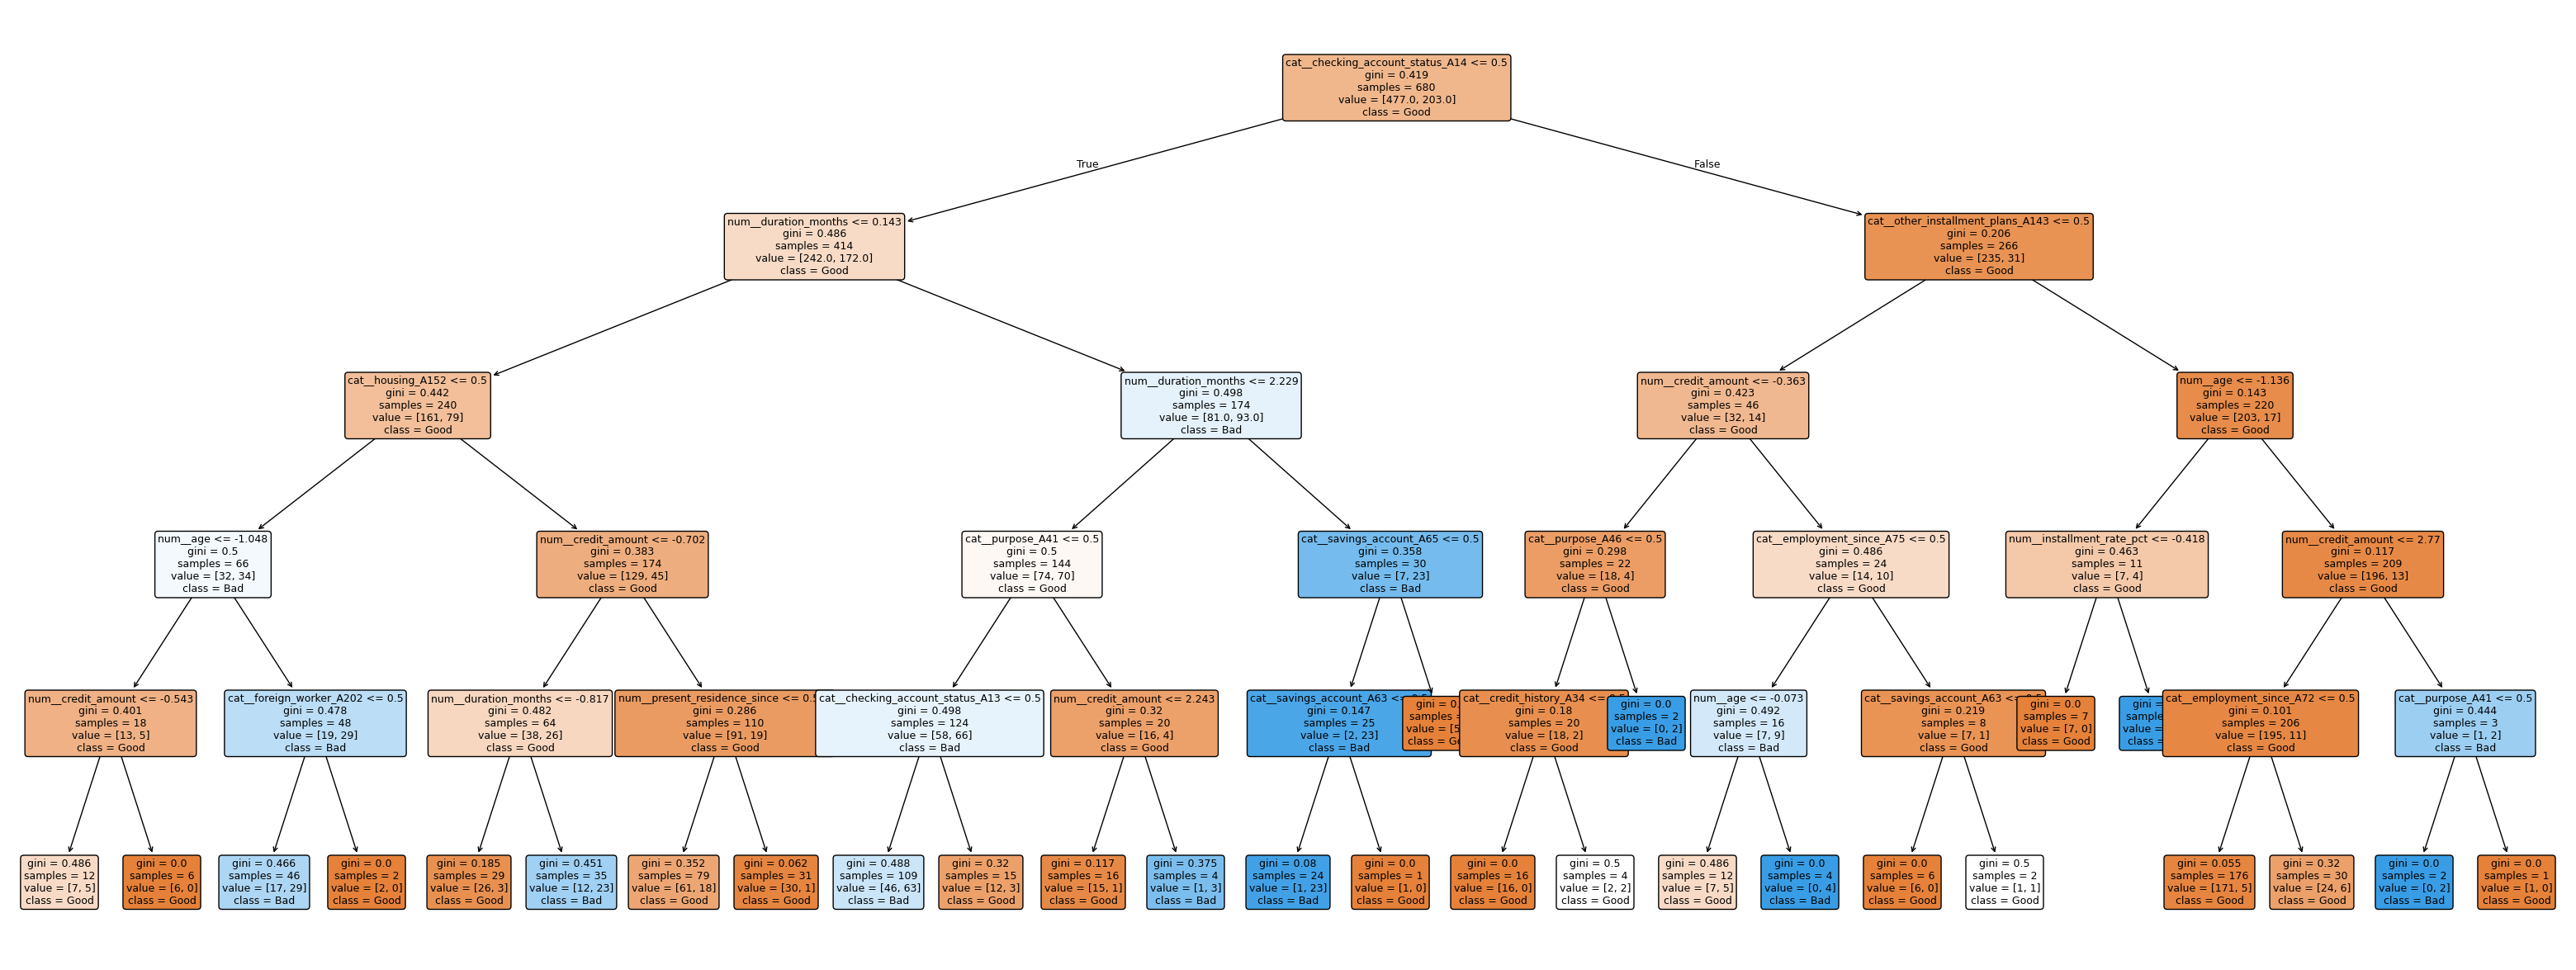

In [249]:
fig, ax = plt.subplots(figsize=(40, 15))
plot_tree(tree, feature_names=list(transformed_features), class_names=["Good", "Bad"], filled=True, rounded=True, fontsize=9, ax=ax, impurity=True)
plt.show()